In [11]:
from tensorflow.keras.datasets import mnist
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
 
# 1.1 Dataset laden

(x_train, y_train), (x_test, y_test) = mnist.load_data()
 
# Überblick verschaffen
print("Trainingsdaten Shape:", x_train.shape)
print("Testdaten Shape:", x_test.shape)
 
 

Trainingsdaten Shape: (60000, 28, 28)
Testdaten Shape: (10000, 28, 28)


In [12]:
# 1.2 DataFrame erstellen 

x_train_flattened = x_train.reshape(x_train.shape[0], 28 * 28)
df_images = pd.DataFrame(x_train_flattened)
print(df_images.head())
 

   0    1    2    3    4    5    6    7    8    9    ...  774  775  776  777  \
0    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
1    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
2    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
3    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
4    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   

   778  779  780  781  782  783  
0    0    0    0    0    0    0  
1    0    0    0    0    0    0  
2    0    0    0    0    0    0  
3    0    0    0    0    0    0  
4    0    0    0    0    0    0  

[5 rows x 784 columns]


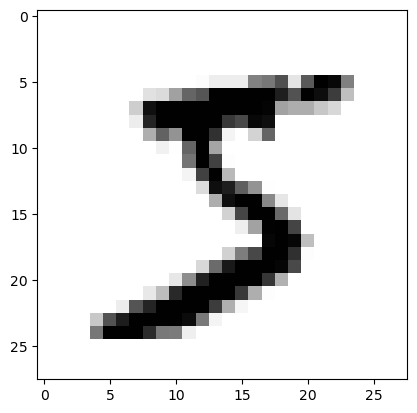

In [13]:
# 1.3 Ziffer an Position 0 anzeigen

plt.imshow(x_train[0], cmap="gray_r")
plt.show()
 

In [18]:
# 1.4 - Warum 10 Knoten im Output-Layer? Weil es 10 Ziffern von 0 bis 9 gibt.
# 1.5 Modell definieren und kompilieren
 
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(64, activation="relu", input_shape=(784,)))
model.add(tf.keras.layers.Dense(10, activation="softmax"))
 
model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
 

In [15]:
# 1.6 Datenaufbereitung (One-Hot & Reshape) & Training

y_train_onehot = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test_onehot = tf.keras.utils.to_categorical(y_test, num_classes=10)
 
# Reshape und Normalisierung der Bilder
x_train = x_train.reshape(x_train.shape[0], x_train.shape[1] * x_train.shape[2])
x_train = x_train.astype("float32") / 255.0
 
x_test = x_test.reshape(x_test.shape[0], x_test.shape[1] * x_test.shape[2])
x_test = x_test.astype("float32") / 255.0
 
# Modell trainieren
history_other = model.fit(
    x_train, 
    y_train_onehot, 
    epochs=5, 
    batch_size=128, 
    validation_data=(x_test, y_test_onehot)
)
 
 

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8981 - loss: 0.3831 - val_accuracy: 0.9353 - val_loss: 0.2252
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9423 - loss: 0.1999 - val_accuracy: 0.9518 - val_loss: 0.1672
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9558 - loss: 0.1533 - val_accuracy: 0.9574 - val_loss: 0.1500
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9641 - loss: 0.1250 - val_accuracy: 0.9654 - val_loss: 0.1234
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9694 - loss: 0.1050 - val_accuracy: 0.9700 - val_loss: 0.1086


In [16]:
# 1.7 Modell validieren / evaluieren

test_loss, test_acc = model.evaluate(x_test, y_test_onehot)
print(f"Testgenauigkeit (Accuracy): {test_acc}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9700 - loss: 0.1086
Testgenauigkeit (Accuracy): 0.9700000286102295
